# Road Safety Rates

How do population-weighted road fatality rates change by year?

Data: [AER/Fatalities](https://vincentarelbundock.github.io/Rdatasets/doc/AER/Fatalities.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Rate uses summed fatalities divided by summed population, per 100,000; states repeat over years.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Road Safety Rates',
 'executed_utc': '2026-11-21T10:14:15.679460+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/Fatalities.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/Fatalities.html',
 'sha256': 'ae265c1b14b4a023179b3af5db33b6a659ccf804987f26e8349826d4083ee149',
 'raw_rows': 336,
 'analysis_rows': 336,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.000000,336
1,state,object,0,0.000000,48
2,year,int64,0,0.000000,7
3,spirits,float64,0,0.000000,157
4,unemp,float64,0,0.000000,100
5,income,float64,0,0.000000,333
6,emppop,float64,0,0.000000,334
7,beertax,float64,0,0.000000,302
8,baptist,float64,0,0.000000,248
9,mormon,float64,0,0.000000,165


## SQL and analysis
Population-weighted annual rate = 100,000 × total fatalities / total population.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "year" AS segment, COUNT(*) AS rows_used, 100000.0 * SUM("fatal") / NULLIF(SUM("pop"),0) AS metric, MIN("fatal") AS minimum, MAX("fatal") AS maximum FROM observations GROUP BY "year" ORDER BY "year";

The largest observed fatalities per 100,000 population is 19.209 for 1988.0. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,1982,48,18.980725,105,4615
1,1983,48,18.190894,94,4573
2,1984,48,18.742980,79,5020
3,1985,48,18.395353,90,4960
4,1986,48,19.180739,100,5253
5,1987,48,19.122693,101,5504
6,1988,48,19.209416,104,5390


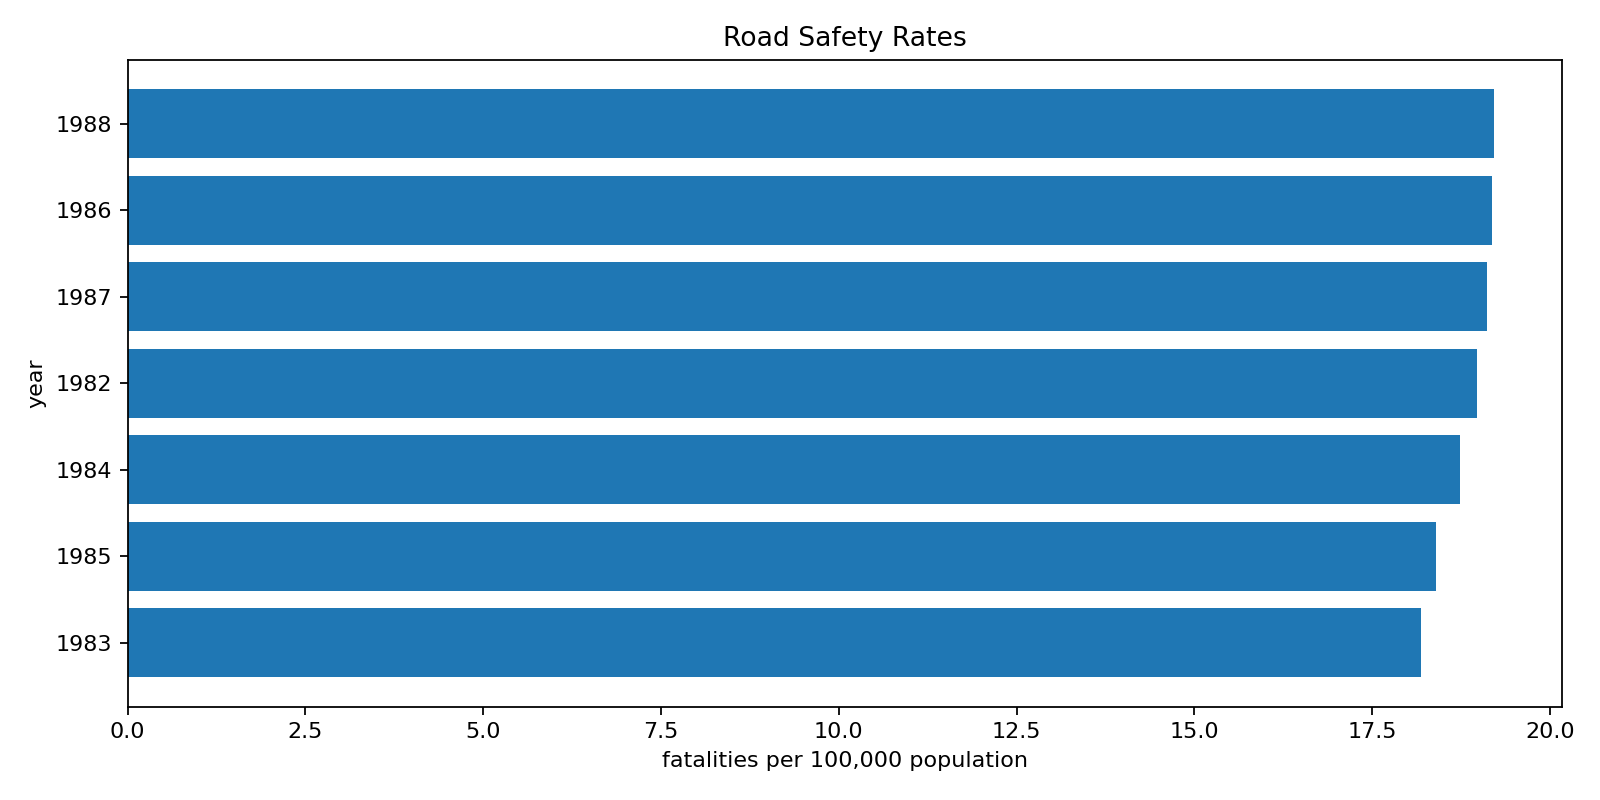

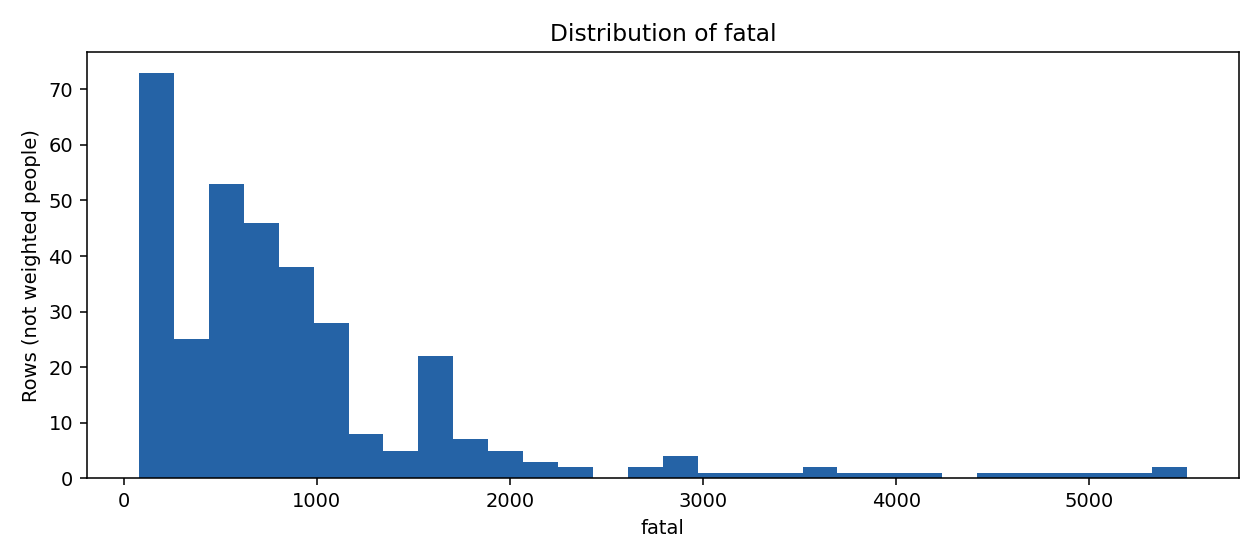

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Rate uses summed fatalities divided by summed population, per 100,000; states repeat over years.

**Next action:** Check exposure in vehicle miles and state-level differences.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.